In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from functools import reduce

Enter the duration of investment (long, mid, short): long


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/lo

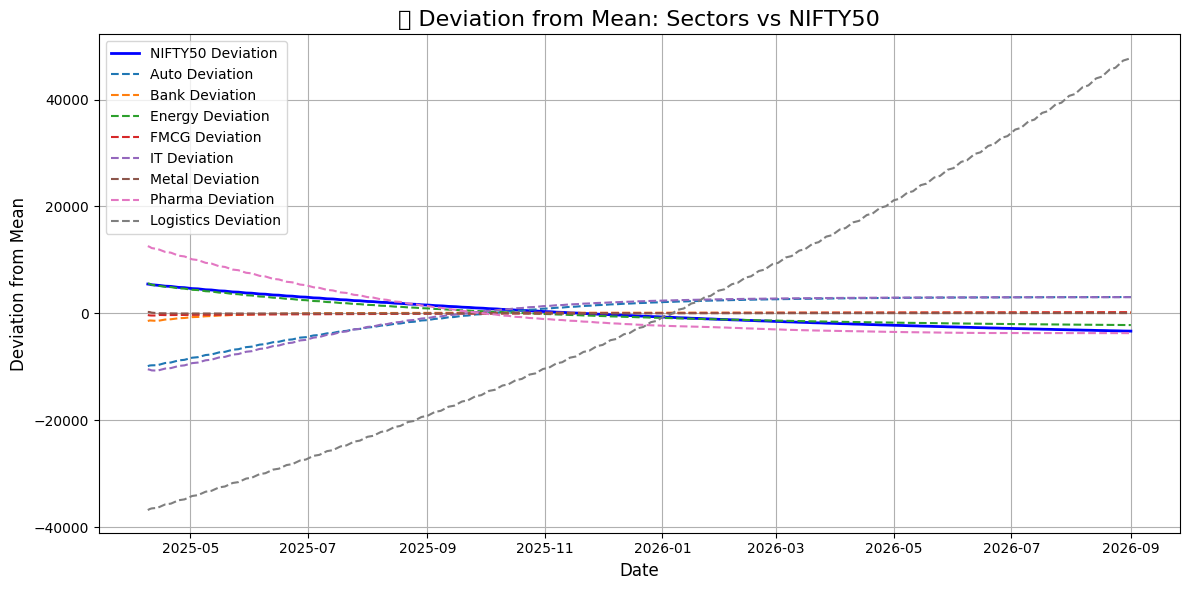

NIFTY50: Mid Risk
Auto: Mid Risk
Bank: Low Risk
Energy: Low Risk
FMCG: Low Risk
IT: Low Risk
Metal: Low Risk
Pharma: High Risk
Logistics: High Risk


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from functools import reduce

# User input for investment duration
term = input("Enter the duration of investment (long, mid, short): ")
forecast_days = 365
if term == "short":
    forecast_days = 90
elif term == "mid":
    forecast_days = 180
elif term == "long":
    forecast_days = 365

# File-to-sector mapping (CSV filename prefix → Sector name)
files_info = {
    "NIFTY 50": "NIFTY50",
    "NIFTY AUTO": "Auto",
    "NIFTY BANK": "Bank",
    "NIFTY ENERGY": "Energy",
    "NIFTY FMCG": "FMCG",
    "NIFTY IT": "IT",
    "NIFTY METAL": "Metal",
    "NIFTY PHARMA": "Pharma",
    "NIFTY TRANSPORTATION & LOGISTICS": "Logistics"
}

# === STEP 1: Load and clean all files ===
processed_data = {}

for raw_name, sector_name in files_info.items():
    filename = f"{raw_name}_Historical_PR_01042010to09042025.csv"
    df = pd.read_csv(filename)

    df['Date'] = pd.to_datetime(df['Date'], format='%d %b %Y')
    df = df[['Date', 'Close']].sort_values('Date').dropna()
    df.rename(columns={'Close': sector_name}, inplace=True)
    df.set_index('Date', inplace=True)
    processed_data[sector_name] = df

# === STEP 2: Merge all data on Date ===
combined_df = reduce(
    lambda left, right: pd.merge(left, right, left_index=True, right_index=True, how='inner'),
    processed_data.values()
)
combined_df.dropna(inplace=True)

# === STEP 3: Forecast with neural networks ===
features = ['Prev_Close', 'MA_5', 'MA_10']
sector_predictions = {}

future_dates = pd.date_range(
    start=combined_df.index[-1] + pd.Timedelta(days=1),
    periods=forecast_days,
    freq='B'
)

for sector in combined_df.columns:
    df = combined_df[[sector]].copy()

    # Feature engineering
    df['Prev_Close'] = df[sector].shift(1)
    df['MA_5'] = df[sector].rolling(window=5).mean()
    df['MA_10'] = df[sector].rolling(window=10).mean()
    df.dropna(inplace=True)

    # Scaling
    scaler = MinMaxScaler()
    df_scaled = pd.DataFrame(
        scaler.fit_transform(df),
        index=df.index,
        columns=df.columns
    )

    X = df_scaled[features].values
    y = df_scaled[sector].values

    # Neural network model
    model = Sequential([
        Dense(64, activation='relu', input_dim=X.shape[1]),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    model.fit(X, y, epochs=30, batch_size=32, verbose=0)

    # Prepare for batch predictions
    last_rows = df_scaled[-10:].values
    predictions_scaled = []

    for _ in range(forecast_days):
        prev_close = last_rows[-1, 0]
        ma_5 = np.mean(last_rows[-5:, 0])
        ma_10 = np.mean(last_rows[-10:, 0])

        input_features = np.array([[prev_close, ma_5, ma_10]])
        pred_scaled = model.predict(input_features, verbose=0)[0][0]

        predictions_scaled.append(pred_scaled)
        new_row = np.array([[pred_scaled, prev_close, ma_5, ma_10]])
        last_rows = np.vstack([last_rows, new_row])[-10:]  # Keep only the last 10 rows

    # Inverse transform
    preds_arr = np.array(predictions_scaled).reshape(-1, 1)
    dummy_cols = np.zeros((len(preds_arr), len(df.columns) - 1))
    full_inverse_input = np.hstack([preds_arr, dummy_cols])
    preds_inverse = scaler.inverse_transform(full_inverse_input)[:, 0]

    sector_predictions[sector] = preds_inverse

# === STEP 4: Plot the results ===
# Compute NIFTY50 deviation from mean
nifty_dev = sector_predictions["NIFTY50"] - np.mean(sector_predictions["NIFTY50"])

# === STEP 5: Compute deviation from mean ===
deviation_data = {}
for sector, preds in sector_predictions.items():
    mean_val = np.mean(preds)
    deviation = preds - mean_val
    deviation_data[sector] = deviation

# === STEP 6: Plot deviation from mean vs NIFTY50 in a single plot ===
plt.figure(figsize=(12, 6))

# Plot NIFTY50 deviation
plt.plot(future_dates, nifty_dev, label='NIFTY50 Deviation', color='blue', linewidth=2)

# Plot deviations for all sectors
for sector, dev in deviation_data.items():
    if sector == "NIFTY50":
        continue  # Skip self (since NIFTY50 is already plotted)
    plt.plot(future_dates, dev, label=f'{sector} Deviation', linestyle='--')

# Add titles and labels
plt.title("📉 Deviation from Mean: Sectors vs NIFTY50", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Deviation from Mean", fontsize=12)

# Display the legend
plt.legend()

# Add grid and adjust layout
plt.grid(True)
plt.tight_layout()

# Show the plot
plt.show()

# === STEP 7: Categorize sectors into risk levels based on variation ===
risk_levels = {}

for sector, preds in sector_predictions.items():
    # Calculate the standard deviation of the predictions
    std_dev = np.std(preds)
    mean_val = np.mean(preds)

    # Calculate the percentage variation
    variation_percentage = (std_dev / mean_val) * 100 if mean_val != 0 else 0
    if sector == "NIFTY50":
        continue
    # Categorize into risk levels
    if variation_percentage > 20:
        risk_levels[sector] = 'High Risk'
    elif 10 < variation_percentage <= 20:
        risk_levels[sector] = 'Mid Risk'
    else:
        risk_levels[sector] = 'Low Risk'

# Print the risk levels for each sector
for sector, risk in risk_levels.items():
    print(f"{sector}: {risk}")
